## Following kernels will load source name text files into a filtered ARCHS4 database

### Function to load sample names from text file

In [16]:
import glob
import sys
import h5py
import archs4py as a4
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def load_sample_names(txt_file_path):
    """Load sample names from a text file"""
    with open(txt_file_path, 'r') as f:
        sample_names = [line.strip() for line in f if line.strip()]
    return sample_names

In [3]:
%cd /scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/
class_sample_dict = dict()

# loop through all file paths in current directory to find files of interest
for filename in glob.glob("*3.txt"):
    file_path = "/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/" + filename
    # sample_names are within the text files and are the values of the class_sample_dict
    sample_names = load_sample_names(file_path)
    # class names are within the names of the text files
    class_name = filename.replace("3.txt","")

    class_sample_dict[class_name] = sample_names

/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering


In [4]:
class_sample_dict

{'Kupffer': ['HUMAN HEPATIC MACROPHAGES',
  'SORTED KUPFFER CELLS',
  'LIVER (HEPATOCYTES + KUPFFER CELLS)',
  'HUMAN KUPFFER CELLS'],
 'Langerhans': ['LANGERHANS CELL-DERIVED DENDRITIC CELL',
  'PANCREATIC ISLETS OF LANGERHANS_BLEO',
  'PANCREATIC ISLETS OF LANGERHANS_VEH',
  'MONOCYTE-DERIVED LANGERHANS CELLS',
  'MONOCYTE-DERIVED LANGERHANS CELL',
  'ISLETS OF LANGERHANS'],
 'Macrophage': ['PCA-ASSOCIATED CD14+CD11B+ MACROPHAGES',
  'WT ESC-DERIVED MACROPHAGE',
  'PERIPHERAL BLOOD MONOCYTE-DERIVED MACROPHAGES',
  'PRIMARY MACROPHAGE',
  'PRIMARY HUMAN MONOCYTE-DERIVED MACROPHAGES, ADMAF, IFN-Î³',
  'MACROPHAGE WITH CONTROL LNA 24H_REP#2',
  'MACROPHAGE_6D_MEDIA_MTB_4H',
  'PRIMARY HUMAN MACROPHAGE CELLS',
  'H1 ESC-DERIVED M1 MACROPHAGES',
  'MACROPHAGES(BC9)',
  'HUMAN MONOCYTE-DERIVED MACROPHAGE',
  'ACTIVATED MONOCYTE-DERIVED MACROPHAGES',
  'PERIPHERAL_BLOOD_MACROPHAGE-M0_SICTRL',
  'IPSC-DERIVED M0 MACROPHAGE',
  'HU-CB-MACROPHAGE-RNA, WT-CB',
  'BONE MARROW DERIVED MACROPHAGE'

### Filters human_tpm_v2.2_NOSC.h5 into a filtered file containing source names in class_sample_dict

In [5]:
transcript_file_path = "/scratch/by2372/pipeline/ARCHS4_Macrophages/human_tpm_v2.2_NOSC.h5"
a4.ls(transcript_file_path)

data                      
│ expression            float32 | (271742, 661840)
meta                      
│ samples                   
│   characteristics_ch1   str    | (661840,)
│   source_name_ch1       str    | (661840,)
│ transcripts               
│   ensembl_id            str    | (271742,)
│   symbol                str    | (271742,)


In [ ]:

with h5py.File(transcript_file_path, "r") as fin, h5py.File('filtered_ARCHS4_7_class.h5', 'w') as fout:

    # copy the ensembl_ids and gene symbols to the new h5 file
    fin.copy("meta/transcripts/ensembl_id", fout)
    fin.copy("meta/transcripts/symbol", fout) 
    
    # Navigate to the metadata group for source names
    source_name_ds = fin['meta/samples/source_name_ch1']

    # Read all names and decode bytes to strings
    source_names = source_name_ds[:]
    if isinstance(source_names[0], bytes):
        source_names = [s.decode('utf-8') for s in source_names]

    # Get dataset info
    expr_dataset = fin['data/expression']
    n_genes, n_samples = expr_dataset.shape

    filtered_dataset = fout.create_dataset(
        "data/filtered_expression",
        (n_genes, 0),                    # start with 0 samples
        maxshape=(n_genes, None),        # allow dynamic extension
        dtype=expr_dataset.dtype,
        chunks=True
    )
    
    class_name_dataset = fout.create_dataset(
        "class_name",
        (0,),                            # start empty
        maxshape=(None,),                # allow appending
        dtype=source_name_ds.dtype,
        chunks=True
    )

    current_pos = 0

    for key, value in class_sample_dict.items():

        print("Matching indices for " + str(key))

        
        matched_indices = []
        class_names = []
        
        for filt_name in set(value): 
            matched_indices.extend([
                i for i, n in enumerate(source_names)
                if n.lower() == filt_name.lower()
            ])

        matched_indices.sort()
        n_new = len(matched_indices)
        print(str(n_new))
        cur_class_names = [key] * n_new
        class_names.append(cur_class_names)

        filtered_dataset.resize((n_genes, current_pos + n_new))
        class_name_dataset.resize((current_pos + n_new,))
        
        # Process in chunks of genes instead of loading all at once
        chunk_size = 1000  # Adjust based on your memory
        iteration = 0
        for start_gene in range(0, n_genes, chunk_size):
            end_gene = min(start_gene + chunk_size, n_genes)
            
            # Read chunk of data for matched samples only
            chunk_data = expr_dataset[start_gene:end_gene, matched_indices]
            
            # Write to output
            filtered_dataset[start_gene:end_gene, current_pos:current_pos + n_new] = chunk_data
            iteration = iteration + 1
            print("Iteration " + str(iteration)+ " is done.")
            sys.stdout.flush()


        class_name_dataset[current_pos:current_pos + n_new] = class_names
        
        current_pos += n_new

Matching indices for Kupffer
35
Iteration 1 is done.
Iteration 2 is done.
Iteration 3 is done.
Iteration 4 is done.
Iteration 5 is done.
Iteration 6 is done.
Iteration 7 is done.
Iteration 8 is done.
Iteration 9 is done.
Iteration 10 is done.
Iteration 11 is done.
Iteration 12 is done.
Iteration 13 is done.
Iteration 14 is done.
Iteration 15 is done.
Iteration 16 is done.
Iteration 17 is done.
Iteration 18 is done.
Iteration 19 is done.
Iteration 20 is done.
Iteration 21 is done.
Iteration 22 is done.
Iteration 23 is done.
Iteration 24 is done.
Iteration 25 is done.
Iteration 26 is done.
Iteration 27 is done.
Iteration 28 is done.
Iteration 29 is done.
Iteration 30 is done.
Iteration 31 is done.
Iteration 32 is done.
Iteration 33 is done.
Iteration 34 is done.
Iteration 35 is done.
Iteration 36 is done.
Iteration 37 is done.
Iteration 38 is done.
Iteration 39 is done.
Iteration 40 is done.
Iteration 41 is done.
Iteration 42 is done.
Iteration 43 is done.
Iteration 44 is done.
Iteration

# Following code will filter the database for TF genes only

In [7]:
filtered_file = "/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/filtered_ARCHS4_7_class.h5"
tf_names = load_sample_names("/scratch/by2372/pipeline/tf_names.txt")
a4.ls(filtered_file)

class_name            str    | (10775,)
data                      
│ filtered_expression   float32 | (271742, 10775)
ensembl_id            str    | (271742,)
symbol                str    | (271742,)


In [8]:
# Read in the filtered ARCHS4 h5 and write out to a new h5
with h5py.File(filtered_file, "r") as fin, h5py.File('filtered_ARCHS4_TFs_7_class.h5', 'w') as fout:

    # Copy the class names into the new h5
    fin.copy("class_name", fout) 
    # Read in the gene symbol and ensembl IDs from the input h5 file
    symbols = fin["symbol"]
    ensembl_id = fin["ensembl_id"]

    # unpack the gene symbol names and decode bytes to strings
    symbols_unpack = symbols[:]
    if isinstance(symbols_unpack[0], bytes):
        symbols_unpack = [s.decode('utf-8') for s in symbols_unpack]

    # unapck the ensembl IDs and decode bytes to strings
    ensembl_unpack = ensembl_id[:]
    if isinstance(ensembl_unpack[0], bytes):
        ensembl_unpack = [s.decode('utf-8') for s in ensembl_unpack]

    # initialize the total number of genes in the input h5, an empty matched index list and the processing chunk size
    n_genes = len(symbols)
    tf_matched_indices = []
    chunk_size = 1000

    # iterate through indices of all genes in the input h5 by chunking through them
    for start_gene in range(0, n_genes, chunk_size):
        end_gene = min(start_gene + chunk_size, n_genes)
        chunk_symbols = symbols_unpack[start_gene:end_gene]

        # find the indices that match the list of known human TFs
        for i, sym in enumerate(chunk_symbols):
            if sym in tf_names:
                idx = start_gene + i
                tf_matched_indices.append(idx)

    tf_matched_indices.sort()
    print("Matched indices for TFs have been found")
    
    # Create output dataset for gene symbol in the output h5
    new_sym_dataset = fout.create_dataset(
        "symbol", 
        (len(tf_matched_indices), ),
        dtype=symbols.dtype,
        chunks=True
    )

    # Create output dataset for ensembl ID in the output h5
    new_ensembl_dataset = fout.create_dataset(
        "ensembl_id", 
        (len(tf_matched_indices), ),
        dtype=ensembl_id.dtype,
        chunks=True
    )

    # convert symbols and ensembl IDs to np arrays
    symbols_arr = np.array(symbols_unpack)
    ensembl_arr = np.array(ensembl_unpack)

    # have only the matched indices be the new symbols and ensembl ID datasets
    new_sym_dataset[...] = symbols_arr[tf_matched_indices]
    new_ensembl_dataset[...] = ensembl_arr[tf_matched_indices]

    # Get dataset info
    expr_dataset = fin['data/filtered_expression']
    n_genes, n_samples = expr_dataset.shape

    # Create output dataset
    filtered_dataset = fout.create_dataset(
        "data/filtered_expression", 
        (len(tf_matched_indices), n_samples),
        dtype=expr_dataset.dtype,
        chunks=True
    )

    # do a chunking approach to chunk through the number of samples in 1000 chunks 
    iteration = 0
    for start_sample in range(0, n_samples, chunk_size):
        end_sample = min(start_sample + chunk_size, n_samples)
        data_chunk = expr_dataset[tf_matched_indices, start_sample:end_sample]
        filtered_dataset[:, start_sample:end_sample] = data_chunk
        print("Iteration " + str(iteration)+ " is done.")
        iteration += 1


Matched indices for TFs have been found
Iteration 0 is done.
Iteration 1 is done.
Iteration 2 is done.
Iteration 3 is done.
Iteration 4 is done.
Iteration 5 is done.
Iteration 6 is done.
Iteration 7 is done.
Iteration 8 is done.
Iteration 9 is done.
Iteration 10 is done.


In [9]:
filtered_TFs_file = "/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/filtered_ARCHS4_TFs_7_class.h5"
a4.ls(filtered_TFs_file)

class_name            str    | (10775,)
data                      
│ filtered_expression   float32 | (13146, 10775)
ensembl_id            str    | (13146,)
symbol                str    | (13146,)


# The code below will create training and testing datasets

In [10]:
def chunk_samples(chunk_size, n_samples, n_genes, output, input):
    iteration = 0
    for start_sample in range(0, n_samples, chunk_size):
        end_sample = min(start_sample + chunk_size, n_samples)

        for start_gene in range(0, n_genes, chunk_size):
            end_gene = min(start_gene + chunk_size, n_genes)

            # Read a chunk of the input matrix
            data_chunk = input[start_sample:end_sample, start_gene:end_gene]

            # Write the chunk to the output dataset
            output[start_sample:end_sample, start_gene:end_gene] = data_chunk

        print("Iteration " + str(iteration) + " (samples " + str(start_sample) + "-" + str(end_sample) + ") is done.")
        iteration += 1

In [11]:
def chunk_class(chunk_size,n_samples,output,input):
    iteration = 0
    for start_sample in range(0, n_samples, chunk_size):
        end_sample = min(start_sample + chunk_size, n_samples)
        data_chunk = input[start_sample:end_sample]
        output[start_sample:end_sample] = data_chunk
        print("Iteration " + str(iteration)+ " is done.")
        iteration += 1

In [14]:
# Make Rows be the samples and the columns be the transcripts
# make it into a data frame and export as H5
with h5py.File(filtered_TFs_file, "r") as fin, h5py.File('filtered_training_7_class.h5', 'w') as ftrain, h5py.File('filtered_testing_7_class.h5', 'w') as ftest:

    # Navigate to the metadata group for class names, gene symbols, and ensembl ID
    class_name_ds = fin['class_name']
    ensembl_id = fin["ensembl_id"]
    symbols = fin["symbol"]

    # Read all names and decode bytes to strings
    symbols_unpack = symbols[:]
    if isinstance(symbols_unpack[0], bytes):
        symbols_unpack = [s.decode('utf-8') for s in symbols_unpack]

    # Read all names and decode bytes to strings
    class_names = class_name_ds[:]
    if isinstance(class_names[0], bytes):
        class_names = [s.decode('utf-8') for s in class_names]

    ensembl_unpack = ensembl_id[:]
    if isinstance(ensembl_unpack[0], bytes):
        ensembl_unpack = [s.decode('utf-8') for s in ensembl_unpack]

    # Navigate to the metadata group for the expression data
    expression = fin["data/filtered_expression"]

    # Transpose expression data so that rows are samples and columns are transcripts
    expression_data = expression[:, :] 
    expression_data = expression_data.T
    print("Expression data has been transposed\n")

    # Make the transcript ID be the symbol _ ensembl ID
    transcript_ID = []
    for idx, sym in enumerate(symbols_unpack):
        ID = sym + "_" + ensembl_unpack[idx]
        transcript_ID.append(ID)

    filtered_df = pd.DataFrame(expression_data,index = class_names, columns = transcript_ID)
    filtered_df['cell_identity'] = class_names

    # Count occurrences of each cell_identity
    cell_identity_counts = filtered_df['cell_identity'].value_counts()
    print(cell_identity_counts)

    # Create a boolean mask to filter rows with cell_identity occurring more than once
    mask = filtered_df['cell_identity'].isin(cell_identity_counts[cell_identity_counts > 1].index)

    # Filter the DataFrame using the mask
    filtered_df = filtered_df[mask]

    # Seperate the ensmbl ids from the cell_identity column
    TFs = filtered_df.columns.drop(['cell_identity'])

    # Set predictors and predicted
    X = np.array(filtered_df[TFs])
    y = np.array(filtered_df['cell_identity'])

    # Train - test split with stratification and shuffling
    ### THIS LOADS IN THE WHOLE H5 FILE TO SPLIT
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=5, stratify=y,shuffle = True)

    # Create output dataset
    X_train_out = ftrain.create_dataset(
        "expression", 
        (X_train.shape[0], X_train.shape[1]),
        dtype=expression.dtype,
        chunks=True
    )
    print("Starting X Train output into H5")
    chunk_samples(1000,X_train.shape[0],X_train.shape[1],X_train_out,X_train)
    print("X Train output successfully")

    y_train_out = ftrain.create_dataset(
        "label",
        len(y_train),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks = True
    )
    print("Starting y train output into H5")
    chunk_class(1000,len(y_train),y_train_out,y_train)
    print("y Train output successfully")

    TF_ID_out = ftrain.create_dataset(
        "TF_ID",
        len(transcript_ID),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks = True
    )
    print("Starting TF IDs output into training H5")
    chunk_class(1000,len(transcript_ID),TF_ID_out,transcript_ID)
    print("TF ID output successfully")
    
    ###export X_test, y_test with Transcript_ID or TFs to an h5
    
    X_test_out = ftest.create_dataset(
        "expression", 
        (X_test.shape[0], X_test.shape[1]),
        dtype=expression.dtype,
        chunks=True
    )
    print("Starting X Test output into H5")
    chunk_samples(1000,X_test.shape[0],X_test.shape[1],X_test_out,X_test)
    print("X test output successfully")

    y_test_out = ftest.create_dataset(
        "label",
        len(y_test),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks = True
    )
    print("Starting y test output into H5")
    chunk_class(1000,len(y_test),y_test_out,y_test)
    print("y test output successfully")

    TF_ID_out = ftest.create_dataset(
        "TF_ID",
        len(transcript_ID),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks = True
    )
    print("Starting TF IDs output into testing H5")
    chunk_class(1000,len(transcript_ID),TF_ID_out,transcript_ID)
    print("TF ID output successfully")



Expression data has been transposed

cell_identity
Monocyte      5497
Macrophage    4183
Microglia      672
alveolar       195
Langerhans     148
Osteoclast      45
Kupffer         35
Name: count, dtype: int64
Starting X Train output into H5
Iteration 0 (samples 0-1000) is done.
Iteration 1 (samples 1000-2000) is done.
Iteration 2 (samples 2000-3000) is done.
Iteration 3 (samples 3000-4000) is done.
Iteration 4 (samples 4000-5000) is done.
Iteration 5 (samples 5000-6000) is done.
Iteration 6 (samples 6000-7000) is done.
Iteration 7 (samples 7000-8000) is done.
Iteration 8 (samples 8000-8081) is done.
X Train output successfully
Starting y train output into H5
Iteration 0 is done.
Iteration 1 is done.
Iteration 2 is done.
Iteration 3 is done.
Iteration 4 is done.
Iteration 5 is done.
Iteration 6 is done.
Iteration 7 is done.
Iteration 8 is done.
y Train output successfully
Starting TF IDs output into training H5
Iteration 0 is done.
Iteration 1 is done.
Iteration 2 is done.
Iteration 3 

In [15]:
train_file = "/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/filtered_training_7_class.h5"
#redownload the most recent transcript file
a4.ls(train_file)

TF_ID                 str    | (13146,)
expression            float32 | (8081, 13146)
label                 str    | (8081,)


In [16]:
test_file = "/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/filtered_testing_7_class.h5"
#redownload the most recent transcript file
a4.ls(test_file)

TF_ID                 str    | (13146,)
expression            float32 | (2694, 13146)
label                 str    | (2694,)


In [17]:
pd.Series(y_train).value_counts()

Monocyte      4123
Macrophage    3137
Microglia      504
alveolar       146
Langerhans     111
Osteoclast      34
Kupffer         26
Name: count, dtype: int64

In [18]:
pd.Series(y_test).value_counts()

Monocyte      1374
Macrophage    1046
Microglia      168
alveolar        49
Langerhans      37
Osteoclast      11
Kupffer          9
Name: count, dtype: int64

### Load in training and testing data here 

In [17]:
f_train = h5py.File("/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/filtered_training_7_class.h5", 'r')
expression_train = f_train['expression'][...]
label_train = f_train['label'][...]
f_train.close()
f_test = h5py.File("/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/filtered_testing_7_class.h5", 'r')
expression_test = f_test['expression'][...]
label_test = f_test['label'][...]

TFs = f_test['TF_ID'][...]

# Read all names and decode bytes to strings
if isinstance(label_train[0], bytes):
    label_train = [s.decode('utf-8') for s in label_train]

# Read all names and decode bytes to strings
if isinstance(label_test[0], bytes):
    label_test = [s.decode('utf-8') for s in label_test]

# Read all names and decode bytes to strings
if isinstance(TFs[0], bytes):
    TFs = [s.decode('utf-8') for s in TFs]

f_test.close()

### SMOTE on Training Data

In [18]:
from imblearn.over_sampling import SMOTE
from collections import Counter

smote = SMOTE(random_state=0,k_neighbors = 1)
expression_SMOTE, label_SMOTE = smote.fit_resample(expression_train,label_train)

print("Original class distribution:", Counter(label_train))
print("Resampled class distribution:", Counter(label_SMOTE))

Original class distribution: Counter({'Monocyte': 4123, 'Macrophage': 3137, 'Microglia': 504, 'alveolar': 146, 'Langerhans': 111, 'Osteoclast': 34, 'Kupffer': 26})
Resampled class distribution: Counter({'Monocyte': 4123, 'Microglia': 4123, 'Macrophage': 4123, 'Langerhans': 4123, 'alveolar': 4123, 'Osteoclast': 4123, 'Kupffer': 4123})


# Below is the code for neural network training

In [2]:
from tensorflow import keras
from sklearn.preprocessing import LabelEncoder
import tensorflow as tef
from keras import optimizers
from keras import losses
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (auc, roc_curve, roc_auc_score)
from tensorflow.keras.models import load_model
import os

2026-04-29 16:21:00.894261: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-04-29 16:21:05.477063: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-04-29 16:21:16.827643: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [20]:
def NN_training(X_train,y_train,X_test,y_test,TFS,name):

    keras.utils.set_random_seed(10)   
    
    num_unique_y = len(set(y_train))

    le = LabelEncoder()
    
    # Fit on training labels (strings) and transform them to integers
    label_train_int = le.fit_transform(y_train)
    
    # Use the same encoder to transform test labels
    label_test_int = le.transform(y_test)
    
    # Best model in magnussen paper was 2 layers of 250 nodes
    model = keras.Sequential([
        keras.layers.Input(shape=(len(TFs),)),  # there are 13146 TFs
        keras.layers.Dense(250, activation='elu'),
        keras.layers.Dense(250, activation='elu'),
        keras.layers.Dense(num_unique_y, activation='softmax')  # For multiclass classification
    ])

    callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience = 3)
    
    adam = optimizers.Adam(
        learning_rate=0.001,
        beta_1=0.9,
        beta_2=0.999,
        weight_decay=0.01  # replaces old `decay`
    )
    model.compile(loss='sparse_categorical_crossentropy',optimizer=adam,metrics=['accuracy'], )
    model.fit(X_train, label_train_int, batch_size=50, epochs=100, verbose=1, validation_split = 0.1, callbacks = [callback])

    model.save("/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/" + name + "_trained_NN.keras")

    np.save("/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/" + name + "_class_names.npy", le.classes_)

    loss, accuracy = model.evaluate(X_test, label_test_int, verbose=1)

    # Predictions on test set
    y_prob = model.predict(X_test)
    y_pred = np.argmax(y_prob, axis=1)

    # Calculate F1 Metrics
    f1_macro = f1_score(label_test_int, y_pred, average='macro')
    f1_weighted = f1_score(label_test_int, y_pred, average='weighted')
    f1_micro = f1_score(label_test_int,y_pred,average = 'micro')

     # binarize the classes
    cell_classes = np.unique(np.concatenate((label_train_int, label_test_int)))
    y_test_bin = label_binarize(label_test_int, classes=cell_classes)

    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    roc_auc_labeled = dict()

    # One vs. rest AUC calculation for multiclass data
    for i in range(len(cell_classes)):
        cur_class = cell_classes[i]
        fpr[cur_class], tpr[cur_class], _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
        roc_auc[cur_class] = auc(fpr[cur_class], tpr[cur_class])
        # Inverse transform the label encoder to get the class label once again
        class_label = le.inverse_transform([cur_class])[0]
        roc_auc_labeled[class_label] = roc_auc[cur_class]
        print(f"AUC for class {cur_class}: {roc_auc[cur_class]:.2f}")

    # compute micro-average ROC curve and ROC area
    fpr["micro"], tpr["micro"],_=roc_curve(y_test_bin.ravel(),y_prob.ravel())
    roc_auc_labeled["micro"] = auc(fpr["micro"],tpr["micro"])   

    return {
    "f1_macro": f1_macro,
    "f1_weighted": f1_weighted,
    "f1_micro": f1_micro,
    "roc_auc_micro": roc_auc_labeled["micro"],
    "roc_auc_per_class": roc_auc_labeled,
    "loss" : loss,
    "accuracy" : accuracy
    }

In [21]:
unbal_metrics = NN_training(expression_train,label_train,expression_test,label_test,TFs,"unbalanced_7_class")


Epoch 1/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8804 - loss: 1.3808 - val_accuracy: 0.9468 - val_loss: 0.2404
Epoch 2/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9589 - loss: 0.2053 - val_accuracy: 0.9518 - val_loss: 0.2042
Epoch 3/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9802 - loss: 0.0689 - val_accuracy: 0.9679 - val_loss: 0.1853
Epoch 4/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9741 - loss: 0.0915 - val_accuracy: 0.9580 - val_loss: 0.2378
Epoch 5/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9748 - loss: 0.0962 - val_accuracy: 0.9530 - val_loss: 0.1883
Epoch 6/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9733 - loss: 0.1578 - val_accuracy: 0.9679 - val_loss: 1.4741
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9670 - loss: 0.2569 
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
AUC for class 0: 1.00
AUC for class 1: 1.00
AUC for class 2: 0.99
AUC for class 3: 1.00
AUC for class 4: 0

In [22]:
unbal_metrics

{'f1_macro': 0.9289679151316008,
 'f1_weighted': 0.9668286780146991,
 'f1_micro': 0.9669636228656273,
 'roc_auc_micro': 0.9974150673855785,
 'roc_auc_per_class': {np.str_('Kupffer'): 0.9954479619284088,
  np.str_('Langerhans'): 0.9999593119653338,
  np.str_('Macrophage'): 0.9930963889249846,
  np.str_('Microglia'): 0.9953813671153339,
  np.str_('Monocyte'): 0.992354770411539,
  np.str_('Osteoclast'): 0.9997966997594281,
  np.str_('alveolar'): 0.9906793719378111,
  'micro': 0.9974150673855785},
 'loss': 0.2569158971309662,
 'accuracy': 0.9669636487960815}

In [23]:
SMOTE_metrics = NN_training(expression_SMOTE,label_SMOTE,expression_test,label_test,TFs,"SMOTE_7_class")

Epoch 1/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.9516 - loss: 0.5104 - val_accuracy: 1.0000 - val_loss: 0.0062
Epoch 2/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9861 - loss: 0.0988 - val_accuracy: 1.0000 - val_loss: 1.0629e-04
Epoch 3/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9894 - loss: 0.0511 - val_accuracy: 1.0000 - val_loss: 8.8267e-05
Epoch 4/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9842 - loss: 0.1328 - val_accuracy: 1.0000 - val_loss: 0.0029
Epoch 5/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9943 - loss: 0.0280 - val_accuracy: 1.0000 - val_loss: 2.7524e-04
Epoch 6/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9969 - loss: 0.0114 - val_accuracy: 1.0000 - val_loss: 2.1667e-04
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9722 - loss: 0.3864 
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
AUC for class 0: 0.99
AUC for class 1: 1.00
AUC for class 2: 0.99
AUC for class 3: 1.00
A

In [24]:
SMOTE_metrics

{'f1_macro': 0.9447114690565926,
 'f1_weighted': 0.972140448663872,
 'f1_micro': 0.9721603563474388,
 'roc_auc_micro': 0.997279520494001,
 'roc_auc_per_class': {np.str_('Kupffer'): 0.9920132422925718,
  np.str_('Langerhans'): 0.9999999999999999,
  np.str_('Macrophage'): 0.9917403794390095,
  np.str_('Microglia'): 0.9996229687441088,
  np.str_('Monocyte'): 0.9941988112566715,
  np.str_('Osteoclast'): 0.9998305831328567,
  np.str_('alveolar'): 0.9999151267312217,
  'micro': 0.997279520494001},
 'loss': 0.38635966181755066,
 'accuracy': 0.9721603393554688}

# Node Light up Test is below

In [3]:
# Import expression data and transcript data from filtered h5 file
filtered_file_tf = h5py.File("/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/filtered_ARCHS4_TFs_7_class.h5", 'r')
ensembl_id = filtered_file_tf['ensembl_id'][...]
symbol = filtered_file_tf['symbol'][...]
expression = filtered_file_tf['data/filtered_expression'][...]
classes = filtered_file_tf['class_name'][...]
filtered_file_tf.close()

# Read all names and decode bytes to strings
if isinstance(ensembl_id[0], bytes):
    ensembl_id = [s.decode('utf-8') for s in ensembl_id]

# Read all names and decode bytes to strings
if isinstance(symbol[0], bytes):
    symbol = [s.decode('utf-8') for s in symbol]

# Read all names and decode bytes to strings
if isinstance(classes[0], bytes):
    classes = [s.decode('utf-8') for s in classes]

# Make the transcript ID be the symbol _ ensembl ID
transcript_ID = []
for idx, sym in enumerate(symbol):
    ID = sym + "_" + ensembl_id[idx]
    transcript_ID.append(ID)

In [9]:
expression

array([[0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.0185731],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       ...,
       [0.0455053, 0.0471331, 0.       , ..., 0.       , 0.0495774,
        0.       ],
       [0.163754 , 0.186552 , 0.0763028, ..., 0.818108 , 0.160071 ,
        0.5938069],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ]], shape=(13146, 10775), dtype=float32)

In [5]:
len(transcript_ID)

13146

In [9]:
len(classes)

10775

In [6]:
class_names = np.load('/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/unbalanced_7_class_class_names.npy')
class_names

array(['Kupffer', 'Langerhans', 'Macrophage', 'Microglia', 'Monocyte',
       'Osteoclast', 'alveolar'], dtype='<U10')

In [7]:
test = np.where(class_names == "Macrophage")
test[0][0]

np.int64(2)

# Obtain Average Expression Values of Key TFs across all classes

In [11]:
def get_average_expression(express_mat,classes_list,TF_list):

    class_values = pd.Series(classes_list).value_counts(sort=False)
    class_dict = dict(zip(class_values.index,list(class_values)))

    TFs_interest = ["ZNF385A_ENST00000394313","ZNF385A_ENST00000546919",
                    "TSC22D1_ENST00000261489","CEBPB_ENST00000303004",
                    "CEBPA_ENST00000498907"]
    output_dict = dict()
    index_start = 0

    for key, value in class_dict.items():
        
        TF_interest_dict = dict()
        index_end = index_start + value
        
        for gene in TFs_interest:
            TF_index = TF_list.index(gene)
            row_avg = np.mean(express_mat[TF_index,index_start:index_end])
            TF_interest_dict[gene] = row_avg

        output_dict[key] = TF_interest_dict
        index_start = index_end

    return(output_dict)

In [12]:
Avg_express = get_average_expression(expression,classes,transcript_ID)

In [13]:
Avg_express

{'Kupffer': {'ZNF385A_ENST00000394313': np.float32(20.383862),
  'ZNF385A_ENST00000546919': np.float32(0.6205754),
  'TSC22D1_ENST00000261489': np.float32(23.918234),
  'CEBPB_ENST00000303004': np.float32(124.49143),
  'CEBPA_ENST00000498907': np.float32(38.765545)},
 'Langerhans': {'ZNF385A_ENST00000394313': np.float32(8.09442),
  'ZNF385A_ENST00000546919': np.float32(0.36359948),
  'TSC22D1_ENST00000261489': np.float32(76.63821),
  'CEBPB_ENST00000303004': np.float32(24.38642),
  'CEBPA_ENST00000498907': np.float32(26.514036)},
 'Macrophage': {'ZNF385A_ENST00000394313': np.float32(79.15438),
  'ZNF385A_ENST00000546919': np.float32(5.45235),
  'TSC22D1_ENST00000261489': np.float32(38.587063),
  'CEBPB_ENST00000303004': np.float32(212.17845),
  'CEBPA_ENST00000498907': np.float32(44.043358)},
 'Microglia': {'ZNF385A_ENST00000394313': np.float32(22.631588),
  'ZNF385A_ENST00000546919': np.float32(6.8330007),
  'TSC22D1_ENST00000261489': np.float32(13.916071),
  'CEBPB_ENST00000303004': 

In [39]:
# Convert nested dict to DataFrame
# output_dict structure: {class: {gene: avg_tpm}}
df = pd.DataFrame(Avg_express).T # rows = classes, columns = genes
df.index.name = "Class"
df = df.reset_index()
df_melted = df.melt(id_vars="Class", var_name="TF", value_name="Average TPM")

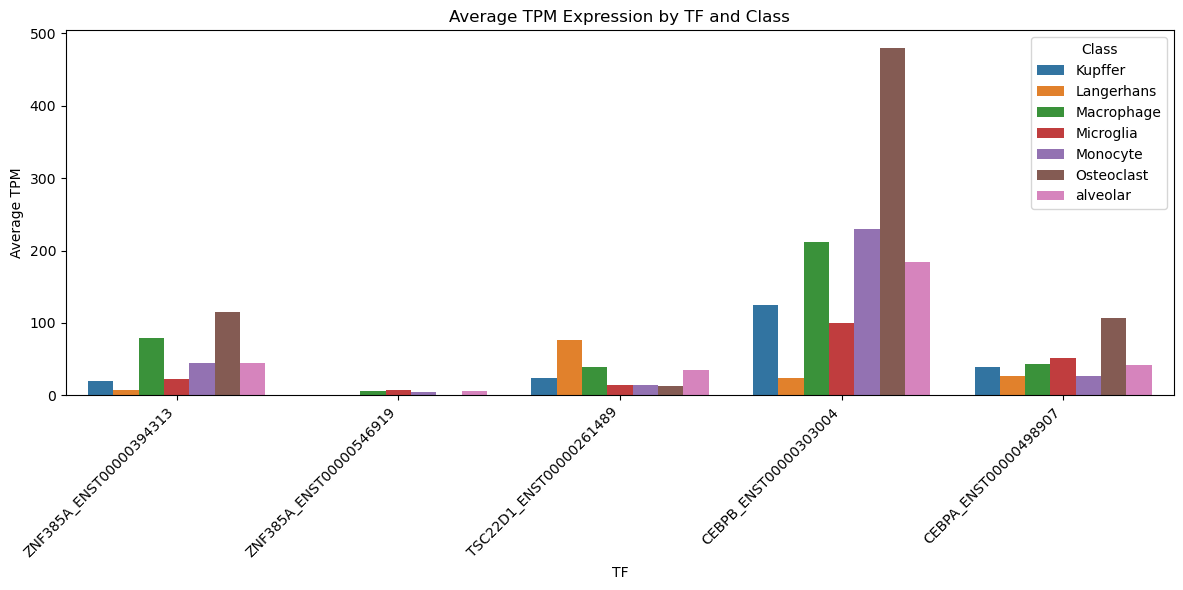

In [26]:
# barplot
plt.figure(figsize=(12, 6))
sns.barplot(data=df_melted, x="TF", y="Average TPM", hue="Class")
plt.xticks(rotation=45, ha="right")
plt.title("Average TPM Expression by TF and Class")
plt.tight_layout()
plt.show()

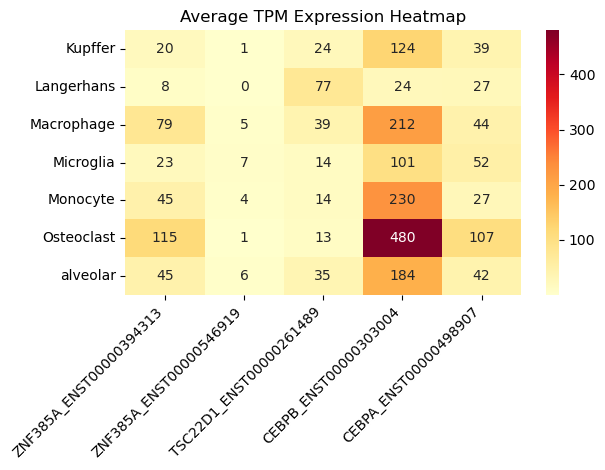

In [32]:
df_heat = pd.DataFrame(Avg_express).T  # rows = classes, columns = TFs
sns.heatmap(df_heat.astype(float), annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("Average TPM Expression Heatmap")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [25]:
df_melted

,Class,TF,Average TPM
0,Kupffer,ZNF385A_ENST00000394313,20.383862
1,Langerhans,ZNF385A_ENST00000394313,8.094420
2,Macrophage,ZNF385A_ENST00000394313,79.154381
3,Microglia,ZNF385A_ENST00000394313,22.631588
4,Monocyte,ZNF385A_ENST00000394313,45.333839
5,Osteoclast,ZNF385A_ENST00000394313,114.964127
6,alveolar,ZNF385A_ENST00000394313,44.568184
7,Kupffer,ZNF385A_ENST00000546919,0.620575
8,Langerhans,ZNF385A_ENST00000546919,0.363599
9,Macrophage,ZNF385A_ENST00000546919,5.452350


### Implement the Node Light up technique as a function

In [8]:
def node_light_up(model_name,tf_names,express_mat,cell_type):
    # load train keras model
    model = load_model('/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/' + model_name + '_trained_NN.keras')
    # create square matrix of zeros. Number of rows and cols is number of TFs
    inp = np.zeros((model.input_shape[1],model.input_shape[1])).T
    # Import cell class names 
    class_names = np.load('/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/' + model_name + '_class_names.npy')

    cell_type_index = np.where(class_names == cell_type)[0][0]
    # Generate baseline TF expression values for the inp square matrix
    tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)
    for i in range(inp.shape[1]):
        inp[i, :] = tf_data.values
    # Generate doubled and halved expression for TFs. Only diagonals of the baseline square matrix is doubled or halved
    half = inp.copy()
    double = inp.copy()
    half[np.eye(half.shape[0]).astype(bool)] = 0.5*half[np.eye(half.shape[0]).astype(bool)]
    double[np.eye(double.shape[0]).astype(bool)] = 2*double[np.eye(double.shape[0]).astype(bool)]

    background_pred = model.predict(inp)
    background_idx = np.argmax(background_pred, axis=1)
    background_labels = class_names[background_idx]
    
    double_pred = model.predict(double)
    double_idx = np.argmax(double_pred, axis=1)
    double_labels = class_names[double_idx]
    
    half_pred = model.predict(half)
    half_idx = np.argmax(half_pred, axis=1)
    half_labels = class_names[half_idx]

    double_background = double_pred[:,cell_type_index] - background_pred[:,cell_type_index]
    half_background = half_pred[:,cell_type_index] - background_pred[:,cell_type_index]

    #score = (double_background - half_background) / 2
    #score = pd.DataFrame(score, index=tf_names, columns=[cell_type])
    #score_sorted = score.sort_values(by=cell_type, ascending=True)
    
    # 7th column is for macrophages classification
    #double_background = (double_pred[:,cell_type_index] - background_pred[:,cell_type_index]) / background_pred[:,cell_type_index]
    double_background = pd.DataFrame(double_background)
    double_background.index = tf_names
    double_background.columns = [cell_type]
    double_background_sorted = double_background.sort_values(by = cell_type, ascending=True)
    
    #half_background = (half_pred[:,cell_type_index] - background_pred[:,cell_type_index]) / background_pred[:,cell_type_index]
    half_background = pd.DataFrame(half_background)
    half_background.index = tf_names
    half_background.columns = [cell_type]
    half_background_sorted = half_background.sort_values(by = cell_type, ascending=False)

    return double_background_sorted, half_background_sorted



In [9]:
unbalanced_macrophages = node_light_up("unbalanced_7_class",transcript_ID,expression,"Macrophage")

2026-04-26 23:14:17.277297: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
/state/partition1/job-7260279/ipykernel_2742358/4172604664.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 


In [10]:
unbalanced_macrophages[0].head(n=20)

,Macrophage
SPI1_ENST00000378538,-0.008538
KLF6_ENST00000497571,-0.005693
ATF4_ENST00000674920,-0.005621
XBP1_ENST00000216037,-0.004802
KLF6_ENST00000542957,-0.004428
CEBPB_ENST00000303004,-0.004408
FOSL2_ENST00000264716,-0.004247
KLF10_ENST00000285407,-0.004118
KMT2A_ENST00000648029,-0.004057
NFKB1_ENST00000652569,-0.003920


In [18]:
for idx, t in enumerate(unbalanced_macrophages[0].index):
    if "ZNF385A_ENST00000546919" in str(t):
        print(idx)

13055


In [12]:
unbalanced_macrophages[1].head(n=20)

,Macrophage
SPI1_ENST00000378538,0.011458
ATF4_ENST00000674920,0.004709
CEBPB_ENST00000303004,0.004637
KLF6_ENST00000497571,0.004544
YBX1_ENST00000436427,0.004043
XBP1_ENST00000216037,0.003646
KLF6_ENST00000542957,0.003137
FOSL2_ENST00000264716,0.002930
KLF10_ENST00000285407,0.002818
KMT2A_ENST00000648029,0.002762


In [24]:
for idx, t in enumerate(unbalanced_macrophages[1].index):
    if "ZNF385A_ENST00000546919" in str(t):
        print(idx)

13057


In [25]:
unbalanced_microglia = node_light_up("unbalanced_7_class",transcript_ID,expression,"Microglia")

/state/partition1/job-7260279/ipykernel_2742358/4172604664.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 


In [26]:
unbalanced_microglia[0].head(n=20)

,Microglia
JUNB_ENST00000302754,-0.000008
YBX1_ENST00000436427,-0.000008
FOS_ENST00000303562,-0.000007
ZNF385A_ENST00000394313,-0.000005
YBX1_ENST00000332220,-0.000004
STAT6_ENST00000300134,-0.000004
KLF10_ENST00000285407,-0.000004
MAFB_ENST00000373313,-0.000004
FOS_ENST00000535987,-0.000004
XBP1_ENST00000216037,-0.000004


In [34]:
for idx, t in enumerate(unbalanced_microglia[0].index):
    if "ZNF385A_ENST00000546919" in str(t):
        print(idx)

12908


In [35]:
unbalanced_microglia[1].head(n=20)

,Microglia
JUNB_ENST00000302754,0.000017
YBX1_ENST00000436427,0.000014
FOS_ENST00000303562,0.000008
YBX1_ENST00000332220,0.000005
ZNF385A_ENST00000394313,0.000004
STAT6_ENST00000300134,0.000004
KLF10_ENST00000285407,0.000003
FOS_ENST00000535987,0.000003
XBP1_ENST00000216037,0.000003
USF2_ENST00000222305,0.000002


In [40]:
for idx, t in enumerate(unbalanced_microglia[1].index):
    if "ZNF385A_ENST00000546919" in str(t):
        print(idx)

12910


In [41]:
unbalanced_monocyte = node_light_up("unbalanced_7_class",transcript_ID,expression,"Monocyte")

/state/partition1/job-7260279/ipykernel_2742358/4172604664.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 


In [42]:
unbalanced_monocyte[0].head(n=20)

,Monocyte
YBX1_ENST00000467957,-0.026597
JUN_ENST00000678696,-0.012345
SPI1_ENST00000227163,-0.010293
EGR1_ENST00000239938,-0.008162
JUN_ENST00000371222,-0.007387
BHLHE40_ENST00000256495,-0.006259
MAFB_ENST00000373313,-0.005402
NFE2L2_ENST00000397062,-0.005123
ATF3_ENST00000341491,-0.004992
BHLHE41_ENST00000242728,-0.004425


In [49]:
for idx, t in enumerate(unbalanced_monocyte[0].index):
    if "ZNF385A_ENST00000546919" in str(t):
        print(idx)

92


In [50]:
unbalanced_monocyte[1].head(n=20)

,Monocyte
YBX1_ENST00000467957,0.005062
JUN_ENST00000678696,0.003570
SPI1_ENST00000227163,0.003002
EGR1_ENST00000239938,0.002693
JUN_ENST00000371222,0.002536
NME2_ENST00000512737,0.002426
BHLHE40_ENST00000256495,0.002259
NFE2L2_ENST00000397062,0.001945
BHLHE41_ENST00000242728,0.001795
ATF3_ENST00000341491,0.001768


In [55]:
for idx, t in enumerate(unbalanced_monocyte[1].index):
    if "ZNF385A_ENST00000546919" in str(t):
        print(idx)

88


In [56]:
unbalanced_alveolar = node_light_up("unbalanced_7_class",transcript_ID,expression,"alveolar")

/state/partition1/job-7260279/ipykernel_2742358/4172604664.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 


In [57]:
unbalanced_alveolar[0].head(n=20)

,alveolar
JUNB_ENST00000302754,-3.333316e-08
ZNF385A_ENST00000394313,-3.053742e-08
MAFB_ENST00000373313,-3.004574e-08
YBX1_ENST00000332220,-2.801118e-08
HMGA1_ENST00000311487,-2.652987e-08
NME2_ENST00000512737,-2.510702e-08
DRAP1_ENST00000312515,-2.409623e-08
KLF6_ENST00000542957,-1.969227e-08
HMG20B_ENST00000333651,-1.954360e-08
FOSL2_ENST00000264716,-1.894086e-08


In [63]:
for idx, t in enumerate(unbalanced_alveolar[0].index):
    if "ZNF385A_ENST00000546919" in str(t):
        print(idx)

12788


In [64]:
unbalanced_alveolar[1].head(n=20)

,alveolar
NME2_ENST00000512737,3.613129e-08
ZNF385A_ENST00000394313,3.117042e-08
JUNB_ENST00000302754,2.977403e-08
YBX1_ENST00000332220,2.564553e-08
MAFB_ENST00000373313,2.346390e-08
HMGA1_ENST00000311487,2.288698e-08
DRAP1_ENST00000312515,2.070066e-08
SPI1_ENST00000378538,1.838998e-08
YBX1_ENST00000436427,1.542578e-08
HMG20B_ENST00000333651,1.417654e-08


In [70]:
for idx, t in enumerate(unbalanced_alveolar[1].index):
    if "ZNF385A_ENST00000546919" in str(t):
        print(idx)

12793


In [71]:
unbalanced_Langerhans = node_light_up("unbalanced_7_class",transcript_ID,expression,"Langerhans")

/state/partition1/job-7260279/ipykernel_2742358/4172604664.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 


In [72]:
unbalanced_Langerhans[0].head(n=20)

,Langerhans
SPI1_ENST00000378538,-2.175133e-08
FOS_ENST00000303562,-1.847352e-08
NME2_ENST00000512737,-1.800830e-08
JUNB_ENST00000302754,-1.497340e-08
YBX1_ENST00000436427,-1.384779e-08
YBX1_ENST00000332220,-1.273081e-08
KLF6_ENST00000497571,-1.156665e-08
ZNF385A_ENST00000394313,-1.048439e-08
HIF1A_ENST00000555014,-1.048060e-08
FOSL2_ENST00000264716,-9.396514e-09


In [77]:
for idx, t in enumerate(unbalanced_Langerhans[0].index):
    if "ZNF385A_ENST00000546919" in str(t):
        print(idx)

12989


In [78]:
unbalanced_Langerhans[1].head(n=20)

,Langerhans
SPI1_ENST00000378538,5.867675e-08
FOS_ENST00000303562,3.253176e-08
NME2_ENST00000512737,2.169983e-08
YBX1_ENST00000436427,1.399177e-08
YBX1_ENST00000332220,1.363605e-08
JUNB_ENST00000302754,1.248062e-08
KLF6_ENST00000497571,9.598624e-09
ZNF385A_ENST00000394313,8.221834e-09
HIF1A_ENST00000555014,7.830982e-09
ATF4_ENST00000674920,7.455954e-09


In [83]:
for idx, t in enumerate(unbalanced_Langerhans[1].index):
    if "ZNF385A_ENST00000546919" in str(t):
        print(idx)

12988


In [84]:
unbalanced_Kupffer = node_light_up("unbalanced_7_class",transcript_ID,expression,"Kupffer")

/state/partition1/job-7260279/ipykernel_2742358/4172604664.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 


In [85]:
unbalanced_Kupffer[0].head(n=20)

,Kupffer
YBX1_ENST00000436427,-8.461571e-09
JUNB_ENST00000302754,-7.139515e-09
SPI1_ENST00000378538,-5.525858e-09
ZNF385A_ENST00000394313,-3.863273e-09
KLF6_ENST00000497571,-3.510638e-09
HIF1A_ENST00000555014,-3.433554e-09
ATF4_ENST00000674920,-3.283938e-09
MAFB_ENST00000373313,-3.146671e-09
KLF6_ENST00000542957,-3.086002e-09
NME2_ENST00000512737,-2.657427e-09


In [90]:
for idx, t in enumerate(unbalanced_Kupffer[0].index):
    if "ZNF385A_ENST00000546919" in str(t):
        print(idx)

12154


In [91]:
unbalanced_Kupffer[1].head(n=20)

,Kupffer
JUNB_ENST00000302754,7.427777e-09
YBX1_ENST00000436427,3.760811e-09
ZNF385A_ENST00000394313,2.809339e-09
KLF6_ENST00000497571,2.362619e-09
HIF1A_ENST00000555014,2.202754e-09
ATF4_ENST00000674920,2.127078e-09
KLF6_ENST00000542957,1.974563e-09
MAFB_ENST00000373313,1.708892e-09
GTF2B_ENST00000370500,1.637660e-09
SPI1_ENST00000378538,1.475380e-09


In [96]:
for idx, t in enumerate(unbalanced_Kupffer[1].index):
    if "ZNF385A_ENST00000546919" in str(t):
        print(idx)

12202


In [97]:
unbalanced_Osteoclast = node_light_up("unbalanced_7_class",transcript_ID,expression,"Osteoclast")

/state/partition1/job-7260279/ipykernel_2742358/4172604664.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 


In [98]:
unbalanced_Osteoclast[0].head(n=20)

,Osteoclast
JUNB_ENST00000302754,-2.675392e-11
YBX1_ENST00000436427,-2.450799e-11
XBP1_ENST00000216037,-1.428810e-11
KLF6_ENST00000497571,-1.352036e-11
STAT6_ENST00000300134,-1.333358e-11
FOS_ENST00000303562,-1.218708e-11
ZNF706_ENST00000517844,-1.186212e-11
FOS_ENST00000554617,-1.185931e-11
NFKB1_ENST00000652569,-1.181218e-11
KLF6_ENST00000542957,-1.179784e-11


In [103]:
for idx, t in enumerate(unbalanced_Osteoclast[0].index):
    if "ZNF385A_ENST00000546919" in str(t):
        print(idx)

13063


In [104]:
unbalanced_Osteoclast[1].head(n=20)

,Osteoclast
JUNB_ENST00000302754,9.539666e-11
YBX1_ENST00000436427,3.986092e-11
XBP1_ENST00000216037,1.207338e-11
STAT6_ENST00000300134,1.081953e-11
KLF6_ENST00000497571,1.064285e-11
ZNF706_ENST00000517844,9.164608e-12
NFKB1_ENST00000652569,8.729127e-12
KLF2_ENST00000248071,8.575652e-12
KLF10_ENST00000285407,8.532812e-12
KLF6_ENST00000542957,8.494627e-12


In [110]:
for idx, t in enumerate(unbalanced_Osteoclast[1].index):
    if "CEBPB_ENST00000303004" in str(t):
        print(idx)

185


# Don't do data balancing for now

In [26]:
SMOTE_macrophages = node_light_up("SMOTE_7_class",transcript_ID,expression,"Macrophage")

/state/partition1/job-4470344/ipykernel_718652/1994595373.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 


In [27]:
SMOTE_macrophages.head(n=20)

,Macrophage
CEBPB_ENST00000303004,-0.008658
JUNB_ENST00000302754,-0.008591
SPI1_ENST00000378538,-0.004856
KLF6_ENST00000542957,-0.004062
ATF4_ENST00000674920,-0.003789
STAT6_ENST00000300134,-0.003295
KMT2A_ENST00000648029,-0.003250
FOS_ENST00000556324,-0.003185
KLF6_ENST00000497571,-0.003105
KLF10_ENST00000285407,-0.003080


In [30]:
for idx, t in enumerate(SMOTE_macrophages.index):
    if "ZNF385A" in str(t):
        print(idx)

225
226
275
305
333
665
1396
2031
2649
4507
10155
12220
12998
12999
13100


In [28]:
SMOTE_microglia = node_light_up("SMOTE_7_class",transcript_ID,expression,"Microglia")

/state/partition1/job-4470344/ipykernel_718652/1994595373.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 


In [29]:
SMOTE_microglia.head(n=20)

,Microglia
MSC_ENST00000325509,-8.422074e-12
FOS_ENST00000303562,-8.115113e-12
JUNB_ENST00000302754,-6.623849e-12
YBX1_ENST00000467957,-5.900301e-12
ZNF385A_ENST00000394313,-5.171133e-12
YBX1_ENST00000332220,-4.445794e-12
BATF_ENST00000286639,-4.425244e-12
PLSCR1_ENST00000342435,-4.052063e-12
ZNF706_ENST00000517844,-3.857379e-12
CEBPD_ENST00000408965,-3.786064e-12


In [31]:
SMOTE_monocyte = node_light_up("SMOTE_7_class",transcript_ID,expression,"Monocyte")

/state/partition1/job-4470344/ipykernel_718652/1994595373.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 


In [32]:
SMOTE_monocyte.head(n=20)

,Monocyte
MSC_ENST00000325509,-0.004995
NME2_ENST00000512737,-0.004678
YBX1_ENST00000467957,-0.004528
JUN_ENST00000678696,-0.003494
NFE2L2_ENST00000397062,-0.003203
SPI1_ENST00000227163,-0.002725
ZNF706_ENST00000519744,-0.002558
JUN_ENST00000371222,-0.002437
CEBPD_ENST00000408965,-0.002197
EGR1_ENST00000239938,-0.002188


In [33]:
for idx, t in enumerate(SMOTE_monocyte.index):
    if "ZNF385A" in str(t):
        print(idx)

45
146
147
925
2984
8656
10494
11111
11750
12480
12812
12840
12870
12919
12920
